# CM laser calibration: alignment → space charge → static (2026-10-22)
K0s runs take ~10 h, so the calibration has to be right on the laser first. Order:
1. **Alignment** of the CM truth to the pad plane (field off: no E×B), checked against the K0s balance of three corrections.
2. **Space charge** from the GEM-current differences between beam blocks of one fill (truth, static and alignment cancel).
3. **Static** at 795xx against the fully aligned truth, with the space charge fixed; target = the K0s-calibrated R².
4. **Second iteration** (field cage + module frames) and the v5 scan that pins down the space-charge profile and the static.
5. **Summary.**

What a TPC-only track keeps of RΔφ(R) = a + bR + cR² + … over 30–76 cm: the R² sagitta (momentum, charge-odd), the
shape beyond the quadratic (resolution), and its pointing (quadratic extrapolated to R = 0). Offset and slope (shift,
rotation) are absorbed. Sector edges (±6°) are excluded everywhere; φ averages are weighted with the K0s-daughter φ distribution.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '/home/yoren/bnl/ROOT/install/lib')
import numpy as np, matplotlib.pyplot as plt
import cmplots as c, truthalign as ta, alignqa as aq, scdiff as sd, scdI_bigscan as sb, calib as cb, slidestyle
plt.rcParams['figure.dpi'] = 80
plt.rcParams.update({'font.size': 14, 'axes.titlesize': 15, 'axes.labelsize': 15, 'legend.fontsize': 11,
                     'xtick.labelsize': 13, 'ytick.labelsize': 13, 'figure.titlesize': 16})
def show(*figs):
    for f in figs:
        display(slidestyle.restyle(f))
    plt.close('all')
ta.correct_truth()

{0: array([-2.02877286, -0.60458442,  0.35802086]),
 1: array([-2.9392519 , -0.34088598,  0.06488564])}

## 1. Alignment: CM truth → pad plane
### 1a. Field off: the R shape a rigid alignment leaves
Rigid CM alignment from field off (S −2.03 mrad, (−0.61, +0.36) mm; N −2.94 mrad, (−0.34, +0.07) mm) plus 36 pad-module
offsets with their ring means removed. Without B there is no E×B: what remains is geometry.

Welcome to JupyROOT 6.30/06


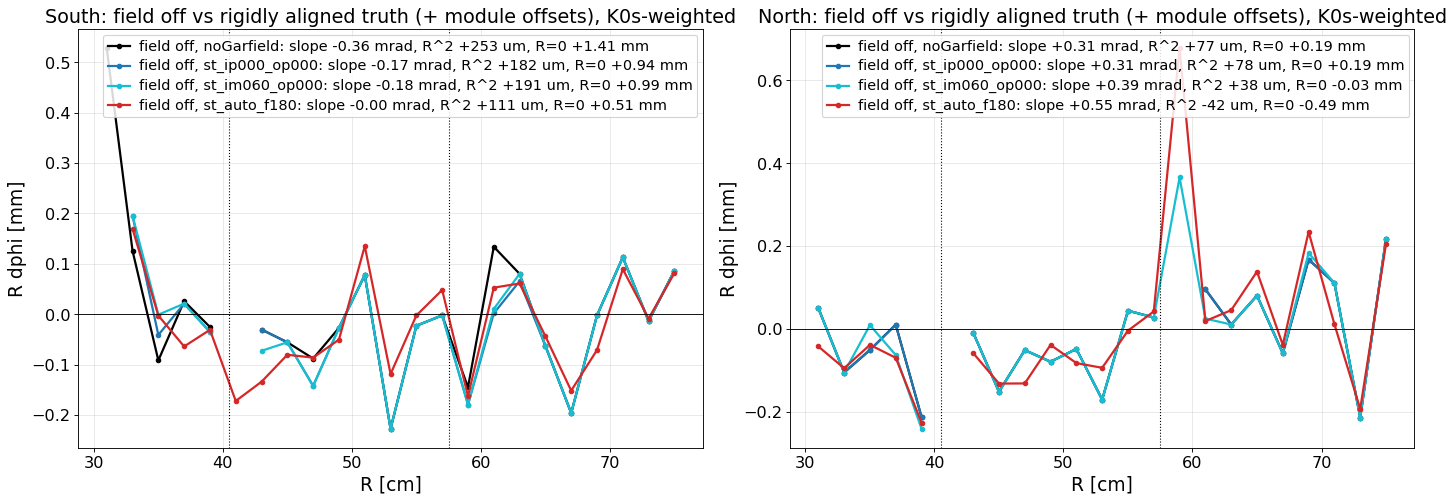

In [2]:
show(aq.fig_zf_alignment())

South +110 … +250 µm, North −40 … +80 µm of R² (range = the field-off correction used). The **full alignment** used from
here on subtracts, from raw field off (no PHGarfield correction: without B nothing moves in RΔφ), the 72 module
offsets and one common fine R profile (2 cm bins, φ-averaged) – it closes exactly in the φ average.

### 1a'. What the alignment is, step by step, and its values
1. **Rigid** CM → pad fit per side on field off, RΔφ only, sector edges excluded: rotation, dx, dy.
2. **72 pad modules** (12 sectors × R1/R2/R3 × 2 sides): median RΔφ per module after the rigid fit, ring mean removed.
3. **Common fine R profile**: median field-off RΔφ per 2 cm in R after steps 1–2 (φ-averaged): the stripe-row
   pattern (±0.2 mm) and the sharp inner-R1 rise in South (+0.6 mm at 31 cm). A coarser sector × 4 cm map (shown for
   its structure) averages that rise away and does not close (R² +157 / +85 µm left).

rigid CM -> pad alignment (field off 78242):
   South: rotation -2.03 mrad, dx -0.60 mm, dy +0.36 mm
   North: rotation -2.94 mrad, dx -0.34 mm, dy +0.06 mm


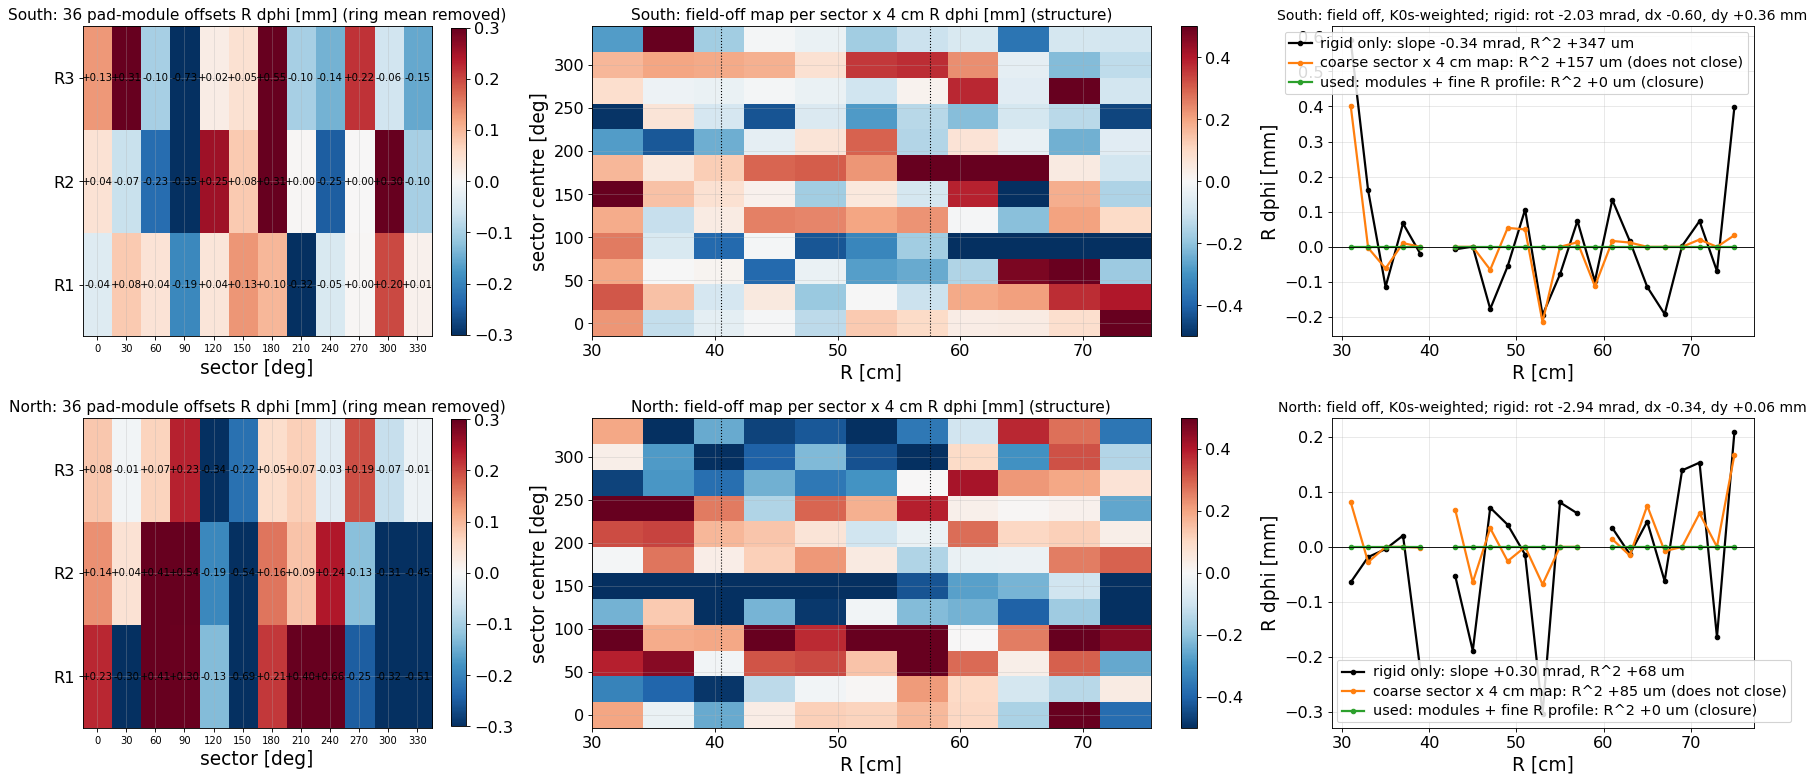

In [3]:
print('rigid CM -> pad alignment (field off 78242):')
for s, (rot, dx, dy) in cb.alignment_values().items():
    print(f"   {c.SIDES[s]:5s}: rotation {rot:+.2f} mrad, dx {dx:+.2f} mm, dy {dy:+.2f} mm")
show(cb.fig_alignment())

**Applying it at the pad plane.** Field off measures the CM pattern relative to the pads; it cannot tell which one moved.
If the CM stripes are where the drawing puts them, the 72 module offsets (up to ±0.3 mm) are pad-module positions and
can be applied to the clusters in local coordinates like a module alignment; the within-module stripe-row pattern
(±0.2 mm, period ~4 cm) looks like CM / pad-row geometry and should stay with the truth.

### 1b. Check against the tracks: K0s balance vs laser R² (795xx)
K0s: (⟨1/pT⁻⟩ − ⟨1/pT⁺⟩)/2 × 11.1 mm, cut03, mass 0.48–0.515 for every correction.

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/alignqa.py:486: RuntimeWarning: Mean of empty slice
  return dec(np.nanmean([wprof(x) for x in xs], axis=0), ta.PRC)


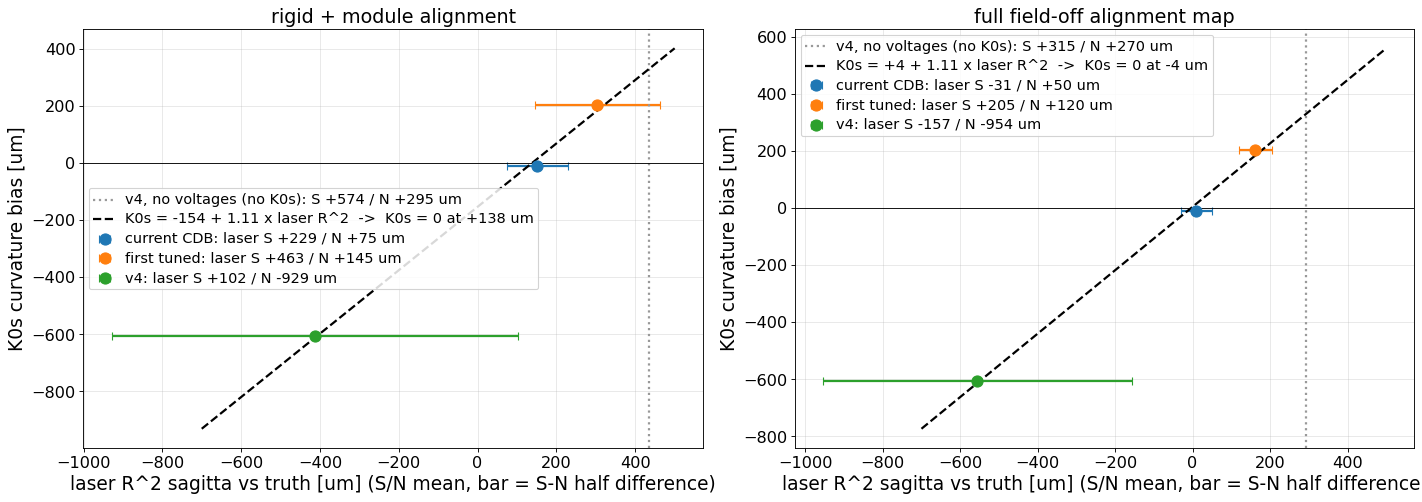

In [4]:
show(aq.fig_k0s_calibration())

With the full alignment: **K0s = +4 + 1.11 × laser R²** (residuals ≤ 25 µm, slope ≈ 1 as it must be): **K0s balance
0 ↔ laser R² ≈ 0** – a correction that matches the aligned CM truth gives balanced K0s. With only the rigid alignment
the zero was at +138 µm; with a PHGarfield-corrected field off as reference it is at +141 µm: the field-off R shape left
in the truth is why "better to the CM" made the tracks worse. (A 17 % N⁻/N⁺ at 2 GeV,
first tuned vs CDB, is ≈ 210 µm of sagitta: the falling spectrum amplifies it.)

### 1c. How good is the CDB, and is it kinky?

In [5]:
for s in (0, 1):
    d = cb.describe(cb.resid('cdb', s))
    print(f"CDB {c.SIDES[s]:5s}: R^2 {d['R2']:+5.0f} um, beyond-quad {d['beyond_quad']*1000:4.0f} um, steps at 40.5 / 57.5 cm {d['step1']:+.2f} / {d['step2']:+.2f} mm, pointing {d['pointing']:+.2f} mm")

CDB South: R^2   -31 um, beyond-quad  195 um, steps at 40.5 / 57.5 cm -0.17 / +0.28 mm, pointing +0.41 mm
CDB North: R^2   +50 um, beyond-quad  106 um, steps at 40.5 / 57.5 cm -0.31 / -0.13 mm, pointing +1.71 mm


/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/calib.py:29: RuntimeWarning: Mean of empty slice
  _cache[k] = np.nanmean([aq.wprof(aq.full_aligned(r, ta.v4_tag(b, tag), s)) for r, b in aq.blocks(runs)], axis=0)


The CDB is on target within ±50 µm (South −31, North +50 µm; target 0) and **not kinky**: module-boundary steps
≤ 0.31 mm, beyond-quadratic 0.11–0.20 mm.

## 2. Space charge from ΔI_GEM (truth-free)
Per CM stripe, the corrected RΔφ is fitted linearly vs the block GEM current: with the static-only correction the slope
is the data space-charge response per µA; with a full correction it is what the model misses.

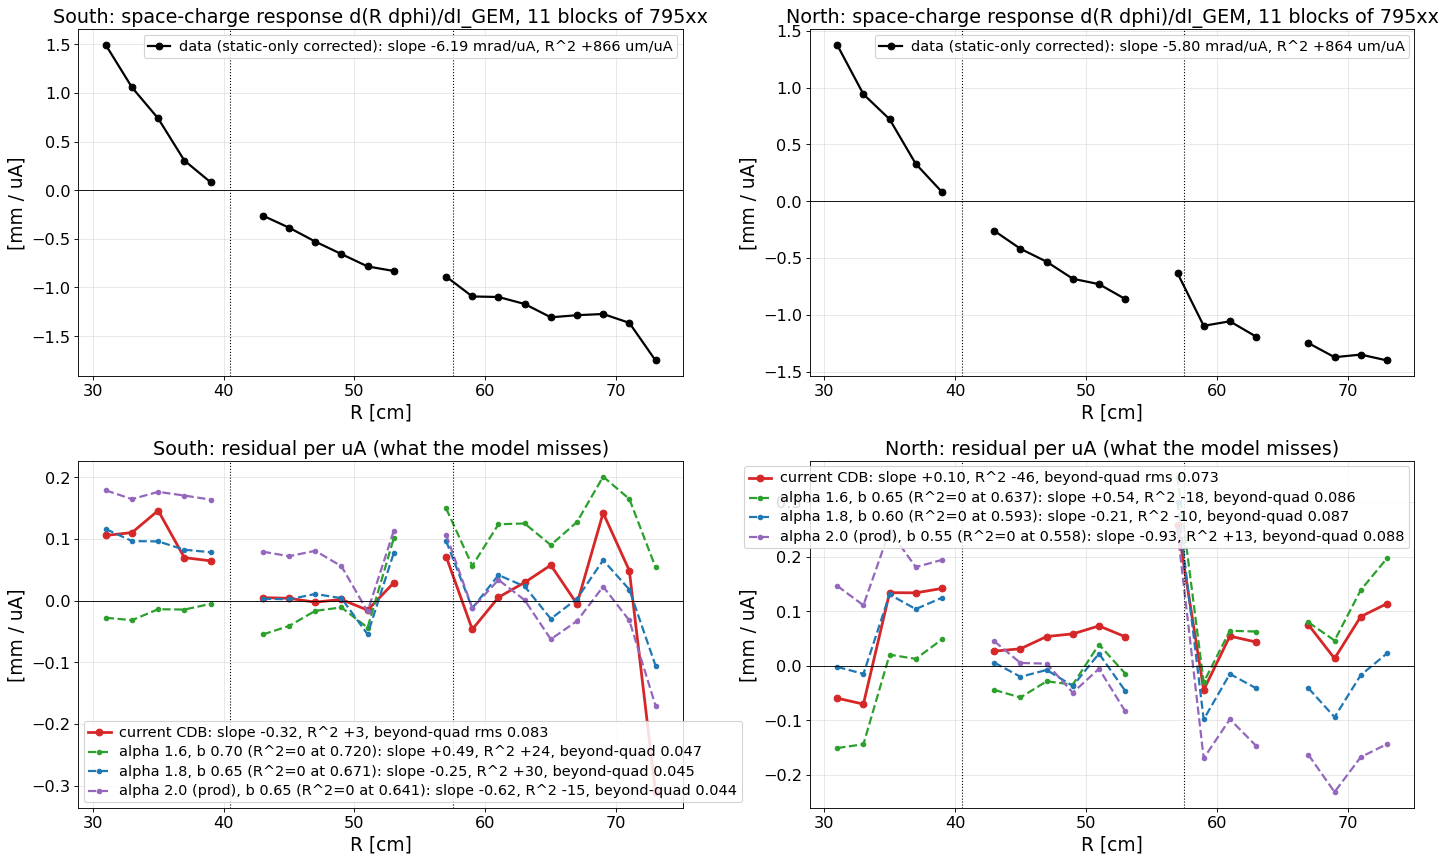

In [6]:
show(sd.fig_response())

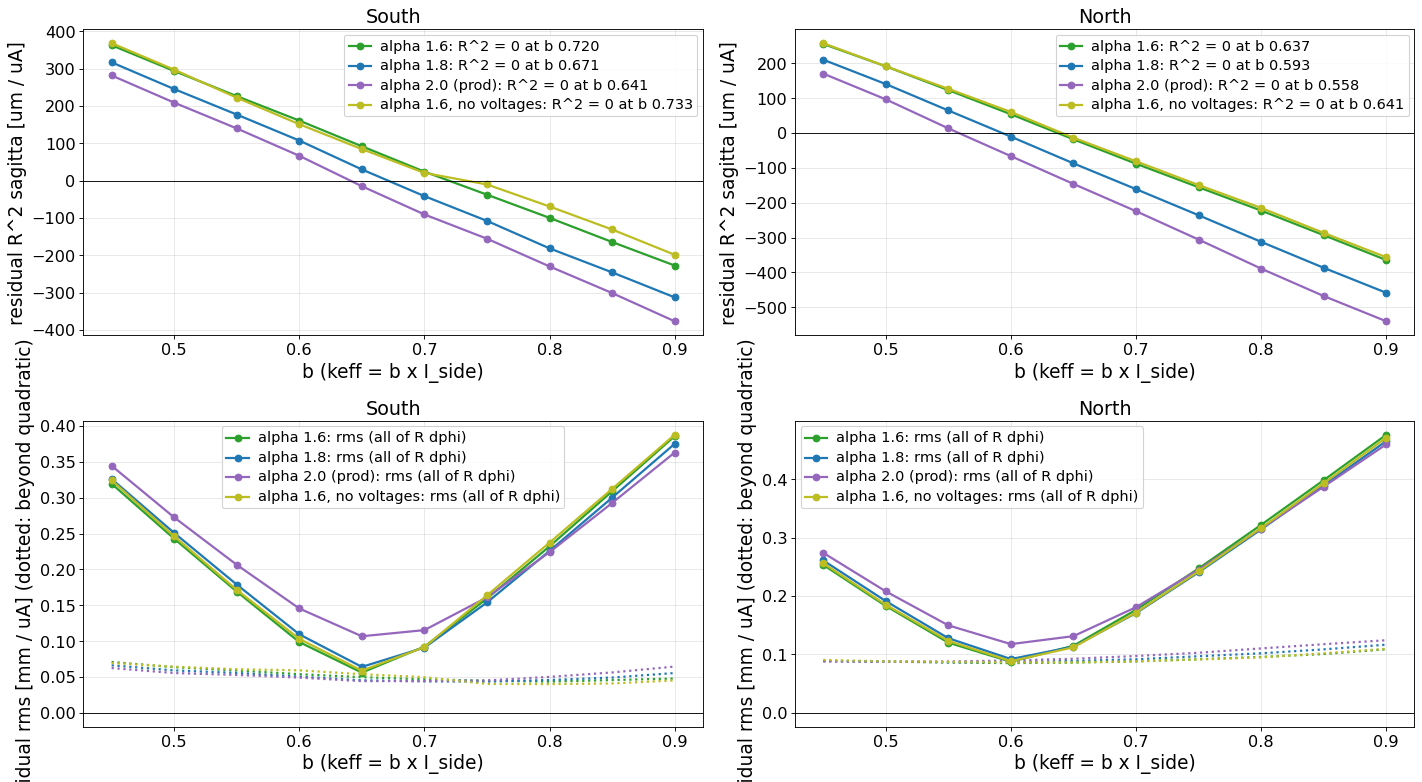

In [7]:
show(sd.fig_bscan())

### 2a. Lever arm: within 795xx, within 80892 / 81558, and across both

In [8]:
print(f"{'map':10s} {'side':6s} {'795xx':>7s} {'808xx/815xx':>12s} {'all (1 intercept)':>18s}   (b where the residual R^2 per uA = 0)")
for lab, side, lo, hi, al in sd.lever_table():
    print(f"{lab:10s} {side:6s} {lo:7.3f} {hi:12.3f} {al:18.3f}")

map        side     795xx  808xx/815xx  all (1 intercept)   (b where the residual R^2 per uA = 0)
alpha 1.6  South    0.720        0.617              0.616
alpha 1.6  North    0.637        0.628              0.550
alpha 1.8  South    0.671        0.570              0.576
alpha 1.8  North    0.593        0.581              0.550
alpha 2.0  South    0.641        0.550              0.552
alpha 2.0  North    0.558        0.550              0.550


**Errors and outliers** (α 1.8; jackknife over blocks; a bootstrap over stripes gives 0.01–0.03; outlier rejection per
stripe at 4 × MAD against mismatched stripes moves b by ≤ 0.01 – every profile is a median over stripes):

| | South | North | S − N |
|---|---|---|---|
| 795xx | 0.686 ± 0.042 | 0.586 ± 0.022 | 0.10 ± 0.05 |
| 80892 / 81558 | 0.569 ± 0.033 | 0.581 ± 0.024 | −0.01 ± 0.04 |
| combined | 0.614 ± 0.026 | 0.584 ± 0.016 | **0.03 ± 0.03** |

- **South and North are consistent with one b** (≈ 0.59–0.61 for α 1.8), as in the CDB; North is the same at low and
  high luminosity (linear in the GEM current); the 795xx South value is 2 σ high.
- Across the two periods (one intercept) b is lower still: a static difference between the periods (months apart)
  enters; cross-period fits need a free intercept per period.

### 2b. Radial profile: α and inner-kink position (big scan, 36 maps, ΔI over the 11 blocks of 795xx)

In [9]:
for s in (0, 1):
    rows = []
    for t in np.unique(sb.data()['tag']):
        if t.startswith('st_') or t == 'cdb':
            continue
        B = sb.best(t, s); rows.append((B['rms'], t, B['b_rms'], B['b_r2']))
    rows.sort()
    print(c.SIDES[s], 'best 8 (rms beyond linear per uA, b at min rms, b at R^2 = 0):')
    for r in rows[:8]:
        print(f"   {r[1]:20s} {r[0]*1000:5.1f} um/uA   b {r[2]:.3f}   b(R^2=0) {r[3]:.3f}")

South best 8 (rms beyond linear per uA, b at min rms, b at R^2 = 0):
   a2p0_r22p75_w2_o0     36.3 um/uA   b 0.550   b(R^2=0) 0.554
   a2p0_r22p75_w4_o0     36.7 um/uA   b 0.550   b(R^2=0) 0.532
   prod2p0               37.5 um/uA   b 0.575   b(R^2=0) 0.563
   a2p0_r25p00_w2_o0     37.8 um/uA   b 0.500   b(R^2=0) 0.516
   a2p0_r25p00_w4_o0     38.4 um/uA   b 0.500   b(R^2=0) 0.499
   a1p8_r22p75_w2_o0     40.5 um/uA   b 0.575   b(R^2=0) 0.590
   a1p8_r25p00_w4_o0     41.0 um/uA   b 0.525   b(R^2=0) 0.530
   a1p8_r22p75_w4_o0     41.0 um/uA   b 0.525   b(R^2=0) 0.570
North best 8 (rms beyond linear per uA, b at min rms, b at R^2 = 0):
   mt3                   33.4 um/uA   b 0.625   b(R^2=0) 0.628
   a1p6_r25p00_w2_o0     38.5 um/uA   b 0.700   b(R^2=0) 0.712
   a1p6_r22p75_w4_o72    39.5 um/uA   b 0.675   b(R^2=0) 0.665
   a2p0_r27p50_w4_o0     39.5 um/uA   b 0.525   b(R^2=0) 0.536
   a1p6_r25p00_w2_o72    39.6 um/uA   b 0.675   b(R^2=0) 0.652
   a2p0_r25p00_w2_o0     40.6 um/uA   b 0.5

The best maps differ by a few µm/µA, at the statistical floor of the 0.93 µA lever arm (single-stripe slopes): α 1.6–2.0
and kink 22.75–27.5 cm cannot be separated on 795xx alone. South leans to α 2.0 / 1.8 at r0 22.75, North to α 1.6 at
r0 25 – **between 1.6 and 1.8, maybe different per side**. The v5 scan adds α 1.7 (exact mixture of the solved 1.6 and
1.8 fields) and the high-luminosity blocks (within-period ΔI) to pin it down.

### 2c. φ dependence of the response

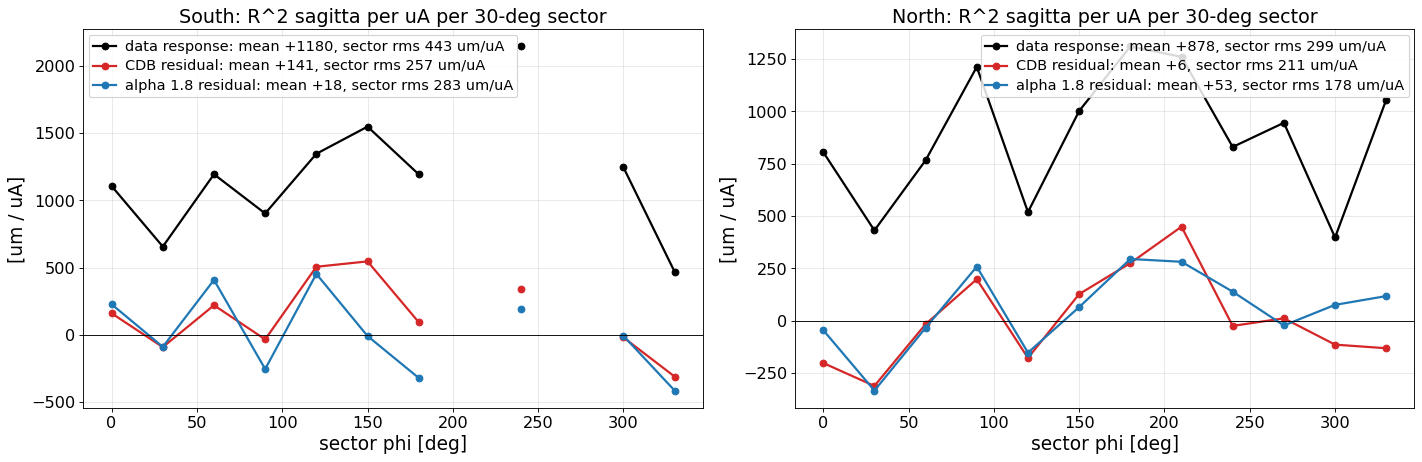

In [10]:
show(sd.fig_sectors())

Sector scatter ≈ 300–450 µm/µA, South first harmonic at ≈ −150°: opposite to the earlier beam − no-beam sine (+70°),
which was therefore a static/alignment change between the beam and the no-beam run, not space charge. **The main φ sine
is alignment** (the full field-off map removes most of it: CDB South pointing 1.85 → 0.55 mm).

## 3. Static at 795xx (space charge fixed)
**What is done, step by step**
1. Space charge fixed from Section 2: α 1.8 at the ΔI b (0.70 S / 0.60 N).
2. Base static = v4 (tilt 0.43 / 1.01 mrad, field map (+3.0, −1.6) mm, IFC S −83 / N −114 V, OFC S +55 / N +209 V vs
   automatic, frames 0) – fitted earlier to the *rigidly* aligned truth.
3. Residual at 795xx vs the **fully** aligned truth, K0s-weighted. Target: R² = 0 (K0s balance 0) and a flat shape.
4. Response of each static knob measured on 75073 (no space charge), same alignment and weighting (3b).
5. Least-squares fit of IFC, OFC and frame charge per side to the target shape (offset and slope free: tracks absorb
   them), with a pull toward 0 V and frames −180 (3c).

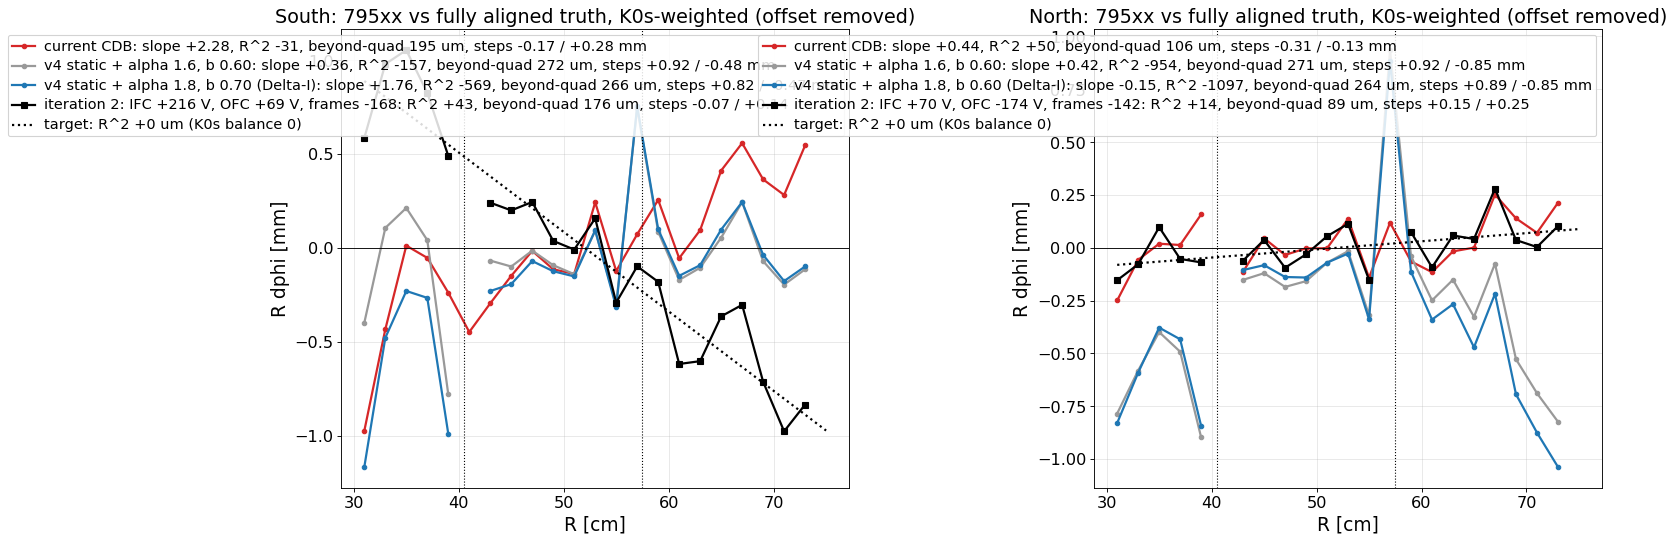

In [11]:
show(cb.fig_static())

### 3b. What each static knob does (75073, offset and slope removed = what a track keeps)

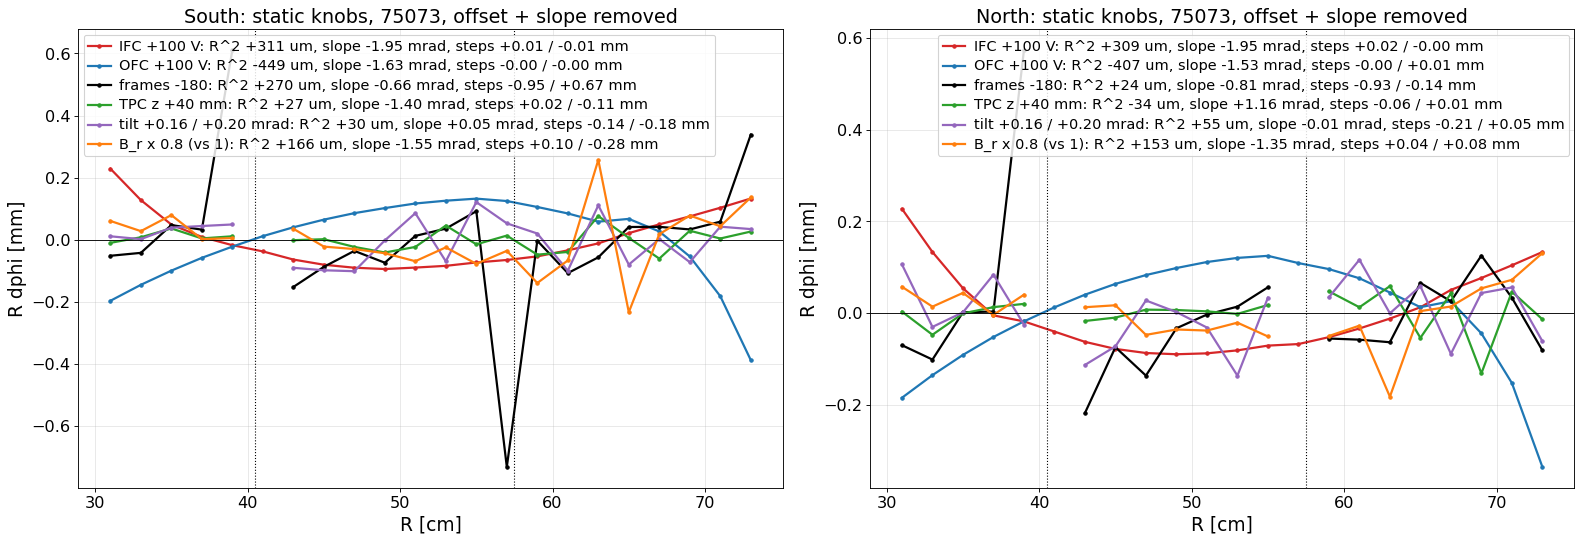

In [12]:
show(cb.fig_responses())

- **IFC**: R² +310 µm per +100 V, smooth. **OFC**: R² −450 / −410 µm per +100 V, smooth: the two curvature knobs.
- **Frames (−180)**: steps at the module boundaries (−0.9 / +0.6 mm South, −1.0 mm at 40.5 cm North).
- **TPC z (+40 mm)**, **tilt**, **B_r × 0.8**: ≤ 160 µm of R², mostly slope / steps; the tilt is a first harmonic in φ
  (nearly zero in the φ average).

### 3c. Fit: how much field cage is really needed

South lambda  0.00: IFC  +133 V, OFC  +124 V (vs auto), frames  -168 -> R^2   +43 um, beyond-quad  176 um, steps -0.07 / +0.14
South lambda  0.01: IFC   +95 V, OFC   +98 V (vs auto), frames  -164 -> R^2   +36 um, beyond-quad  177 um, steps -0.05 / +0.13
South lambda  0.03: IFC   +58 V, OFC   +72 V (vs auto), frames  -160 -> R^2   +32 um, beyond-quad  180 um, steps -0.03 / +0.11
South lambda  0.10: IFC   +20 V, OFC   +43 V (vs auto), frames  -156 -> R^2   +39 um, beyond-quad  184 um, steps -0.00 / +0.10
South lambda  0.30: IFC    +3 V, OFC   +25 V (vs auto), frames  -155 -> R^2   +68 um, beyond-quad  187 um, steps -0.00 / +0.10
South lambda  1.00: IFC    -1 V, OFC   +12 V (vs auto), frames  -161 -> R^2  +120 um, beyond-quad  189 um, steps -0.03 / +0.13
South lambda  3.00: IFC    -1 V, OFC    +5 V (vs auto), frames  -170 -> R^2  +164 um, beyond-quad  190 um, steps -0.08 / +0.16
North lambda  0.00: IFC   -44 V, OFC   +35 V (vs auto), frames  -142 -> R^2   +14 um, beyond-quad   89 um, step

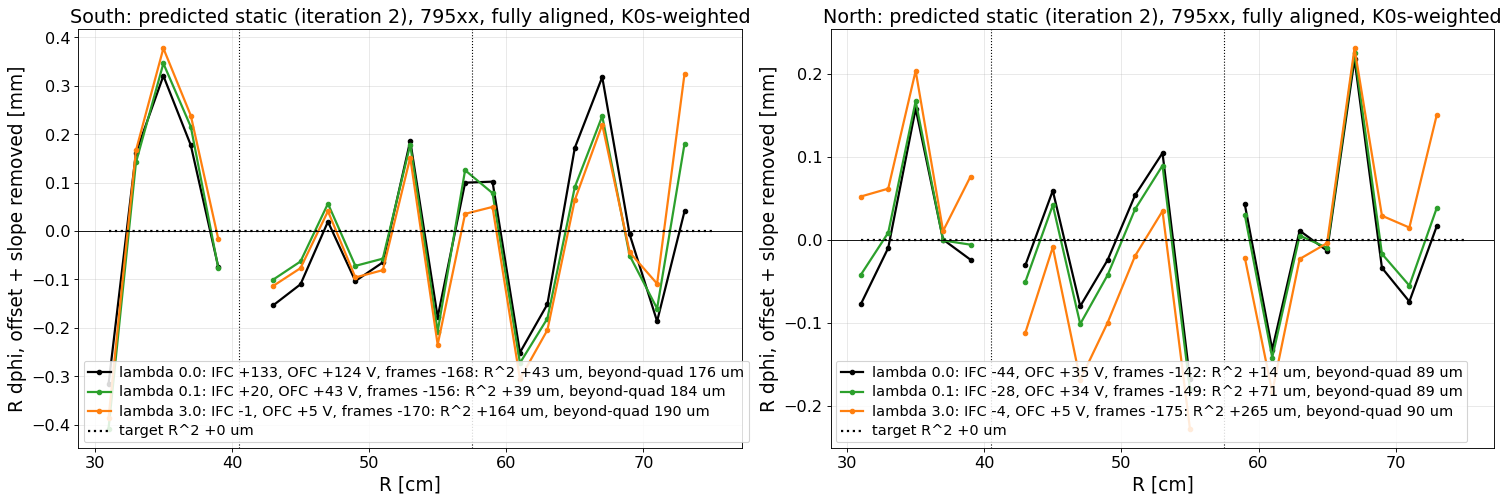

In [13]:
for s in (0, 1):
    for r in cb.ridge(s, lams=(0, 0.01, 0.03, 0.1, 0.3, 1, 3)):
        print(f"{c.SIDES[s]:5s} lambda {r['lam']:5.2f}: IFC {r['IFC']:+5.0f} V, OFC {r['OFC']:+5.0f} V (vs auto), frames {r['frames']:+5.0f} -> R^2 {r['R2']:+5.0f} um, beyond-quad {r['beyond_quad']*1000:4.0f} um, steps {r['step1']:+.2f} / {r['step2']:+.2f}")
show(cb.fig_ridge())

- The fit is flat: smaller voltages cost little. **Preferred (λ = 0.1)**: South IFC +20, OFC +43 V, frames −156;
  North IFC −28, OFC +34 V, frames −149 → R² +39 / +71 µm, shape at or below the CDB level (0.18 / 0.09 mm beyond
  the quadratic; CDB 0.20 / 0.11). **Nearly symmetric: IFC ≈ 0, OFC ≈ +35 … +45 V, frames ≈ −150.**
- With no field-cage change at all (λ = 3) R² is ≈ +160 … +260 µm too curved: the OFC only has to remove that.
  The frames go back to ≈ −150 … −170 (CDB −180) in every fit.

### 3d. Frame physics check (fine R)

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/calib.py:230: RuntimeWarning: Mean of empty slice
  return np.nanmean([fp(aq.full_aligned(r, ta.v4_tag(b, tag), s)) for r, b in aq.blocks()], axis=0)


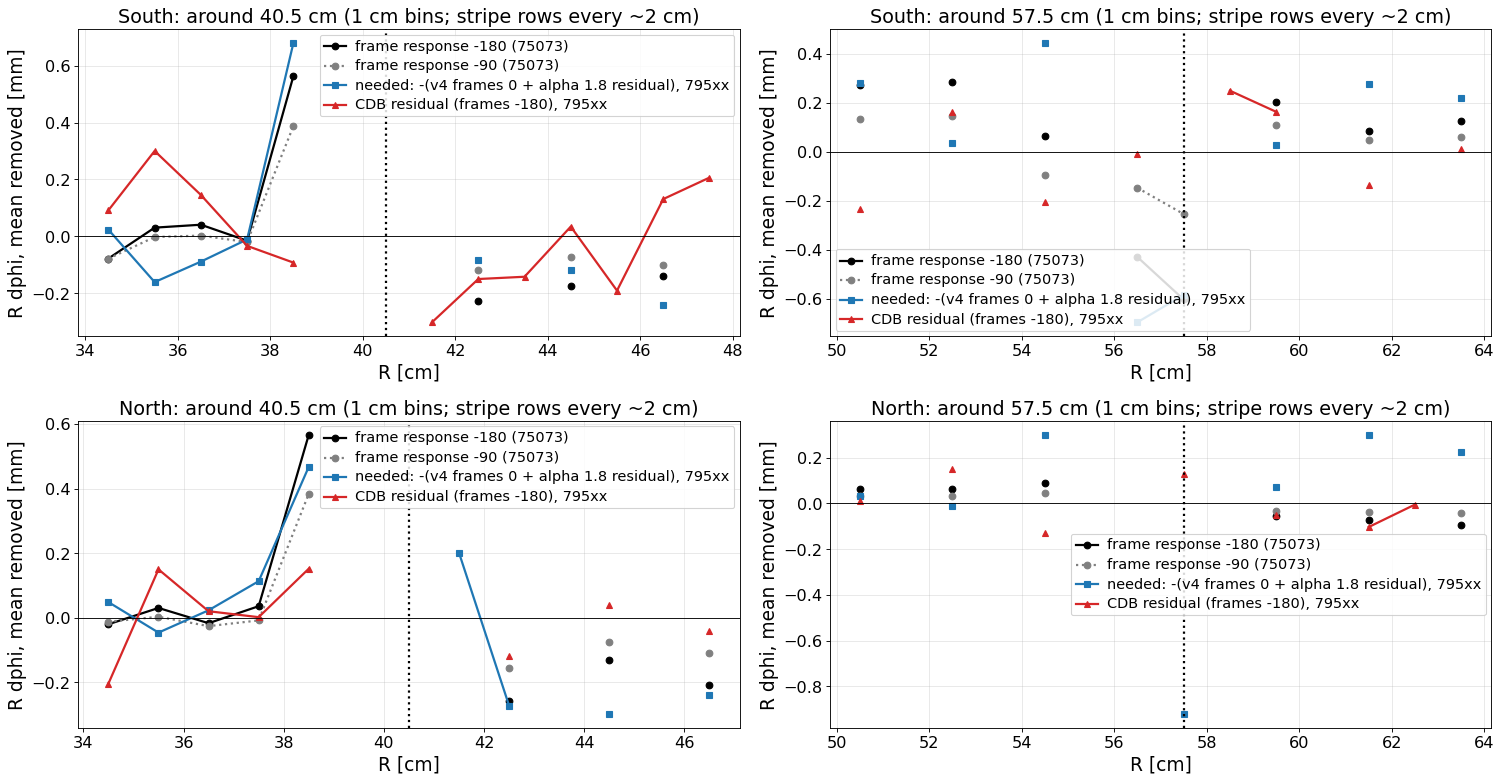

In [14]:
show(cb.fig_frames_fine())

- The frame effect sits in the **last stripe row before each boundary** (stripe rows every ~2 cm: anything steeper
  cannot be seen). Where both exist, the −180 model matches what is needed: South 40.5 cm +0.53 vs +0.57 mm, South
  57.5 cm −0.72 vs −0.65 mm; North 40.5 cm the model is ~70 % too strong (+0.59 vs +0.35 mm).
- North 57.5 cm: the 75073 frame scan has **no clusters at 56–58 cm** (the coarse "−0.14 mm" North response there was
  missing data); 795xx needs −0.94 mm in the last row. Tails away from the boundaries agree (0.1–0.3 mm).
- A localised frame field (cut at a few cm in r / rφ and ~10 cm from the readout in z, against the truncated-harmonic
  ringing) can be made by post-processing the CDB frame maps (`Tpc_PolySeeding_ModuleFrames3D_Side0/1`, which carry the
  frame pattern `hFrameGeometry`) and passing them with `PHGarfield::SetFrameElectricFieldMap3D`.

### 3e. Per sector

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/calib.py:117: RuntimeWarning: Mean of empty slice
  D = np.nanmean(D, axis=0)


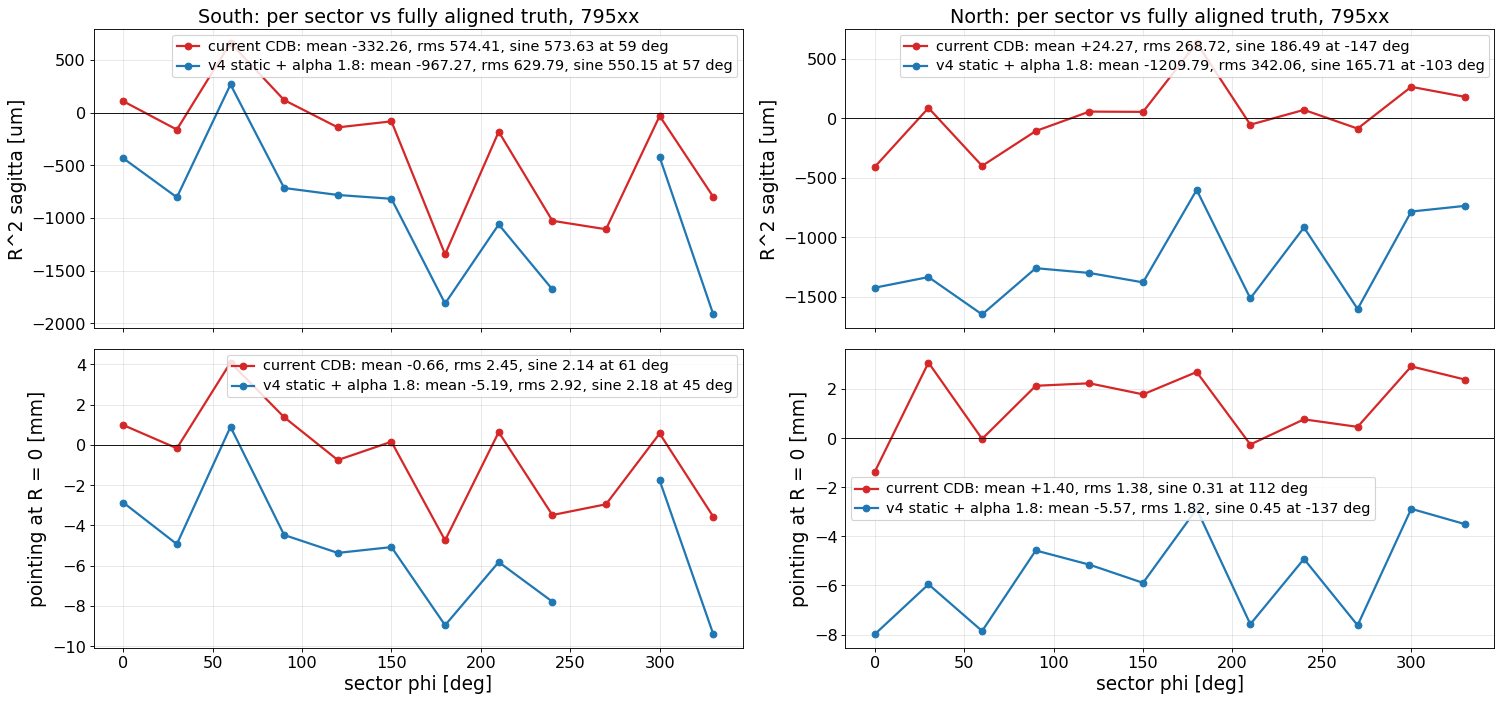

In [15]:
show(cb.fig_static_sectors())

## 4. The v5 scan (prepared: `cm_laser/make_v5_scan.py`, copied to SDCC)
Geometry: survey x/y, **z −7.1 mm (CDB TPC centre)**, tilt 0.43 / 1.01 mrad, field map (+3.0, −1.6) mm. Static centre
= iteration 2 (per side). Both sides are independent drift volumes: one config sets both, each side is analysed alone.

| part | what | where | jobs |
|---|---|---|---|
| S | static grid: centre + IFC {−60, 0, +60} × OFC {−80, 0, +80} × frames {−60, 0, +60} V/units; static-only and with α 1.8 at the ΔI b | 11 blocks 795xx, 75073, 83319, 78242 | 114 |
| M | maps α {1.6, 1.7, 1.8, 2.0} × kink {22.75, 25.0, 27.5} cm (1.7: 22.75 / 25) × b {0.50 … 0.80} + static-only | 17 blocks (795xx, 80892, 81558) | 221 |
| X | the same map scan on 6 extra blocks (3000 / 4000), after their 600 pad jobs | 79513/16/29, 80892, 81558 | 78 (+600 pads) |

Analysis plan: ΔI per stripe within each period (free intercept per period) → α, kink, b per side; then the static grid
vs the fully aligned truth, K0s-weighted, target R² 0 and flat shape; field off / no beam as checks of the frames
and field cage (same static, no space charge).

## 5. Summary
1. **Alignment**: the CM truth needs the full field-off map (not only a rigid fit). With it, three corrections and their
   K0s balance lie on K0s = +4 + 1.11 × laser R²: matching the aligned CM truth = balanced K0s. The CM is the
   calibration tool for the curvature.
2. **The CDB is good**: R² −31 / +50 µm vs the target 0, not kinky (steps ≤ 0.31 mm). Its φ sine is mostly alignment.
3. **Space charge** (truth-free ΔI, robust against mismatches): one b for both sides (α 1.8: 0.61 ± 0.03 S,
   0.58 ± 0.02 N), linear in the GEM current. Radial profile between α 1.6 and 1.8; the kink position needs the v5 scan
   (and higher-current runs of the same period, if they have laser data).
4. **Static**: our v4 was kinky (frames 0) and had the wrong curvature, both from the misaligned truth. Iteration 2:
   **frames ≈ −150, IFC ≈ 0, OFC ≈ +35 … +45 V on both sides** (small voltages cost little) → R² +40 … +70 µm, CDB-like
   shape. Frame physics matches at the last stripe row except North 40.5 cm (model too strong); North 57.5 cm untested
   (no clusters in the frame scan) → v5 static grid.
5. **K0s φ asymmetry** (40 % at +90°, pair-level, all masses): not from these distortions – separate V0-finding study.